In [ ]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving random-forest (1) (2).ipynb to random-forest (1) (2).ipynb


In [ ]:
df = pd.concat([X,y],axis = 1)

In [ ]:
df.head(8)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no


In [ ]:
df.tail(5)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.isnull().sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df.isnull().values.any())

True


In [ ]:
print(df.isnull().values.any())

True


PHASE 1:

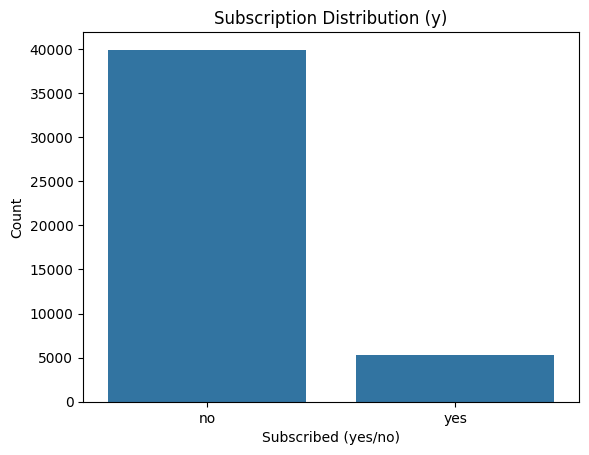

In [ ]:
import matplotlib.pyplot as plt

sns.countplot(x='y', data=df)
plt.title("Subscription Distribution (y)")
plt.xlabel("Subscribed (yes/no)")
plt.ylabel("Count")
plt.show()

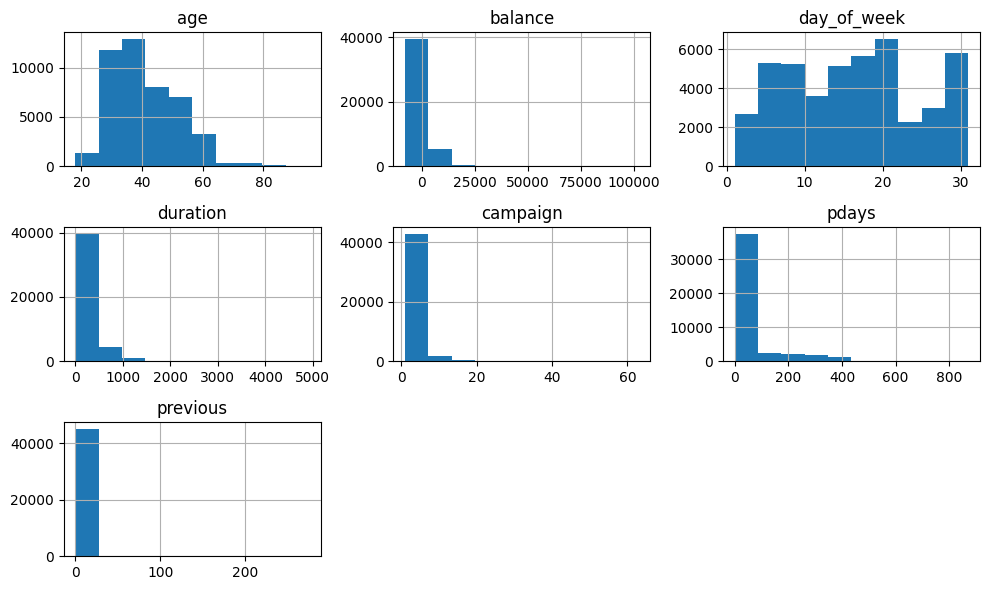

In [ ]:
# Feature distributions
df.hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

In [ ]:
# Missing Value treatment
for col in df.select_dtypes(include = 'object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day_of_week,0


In [ ]:
# Encoding
df['y'] = df['y'].map({'no': 0, 'yes': 1})

In [ ]:
from sklearn.model_selection import train_test_split

# Splitting the data into training and testing sets using the correct target column 'y'
X = df.drop('y', axis=1)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36168, 16)
Testing data: (9043, 16)


PHASE 3:

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Perform one-hot encoding on the DataFrame to handle categorical columns
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# Split features and target
X_encoded = df_encoded.drop('y', axis=1)
y = df_encoded['y']

# Split into training and test sets
X_train_encoded, X_test_encoded, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train the model
model.fit(X_train_encoded, y_train)

# Predict test results
y_pred = model.predict(X_test_encoded)

# Display results
print("Random Forest model trained successfully!")
print("Predicted results:", y_pred)

Random Forest model trained successfully!
Predicted results: [0 0 0 ... 0 0 0]


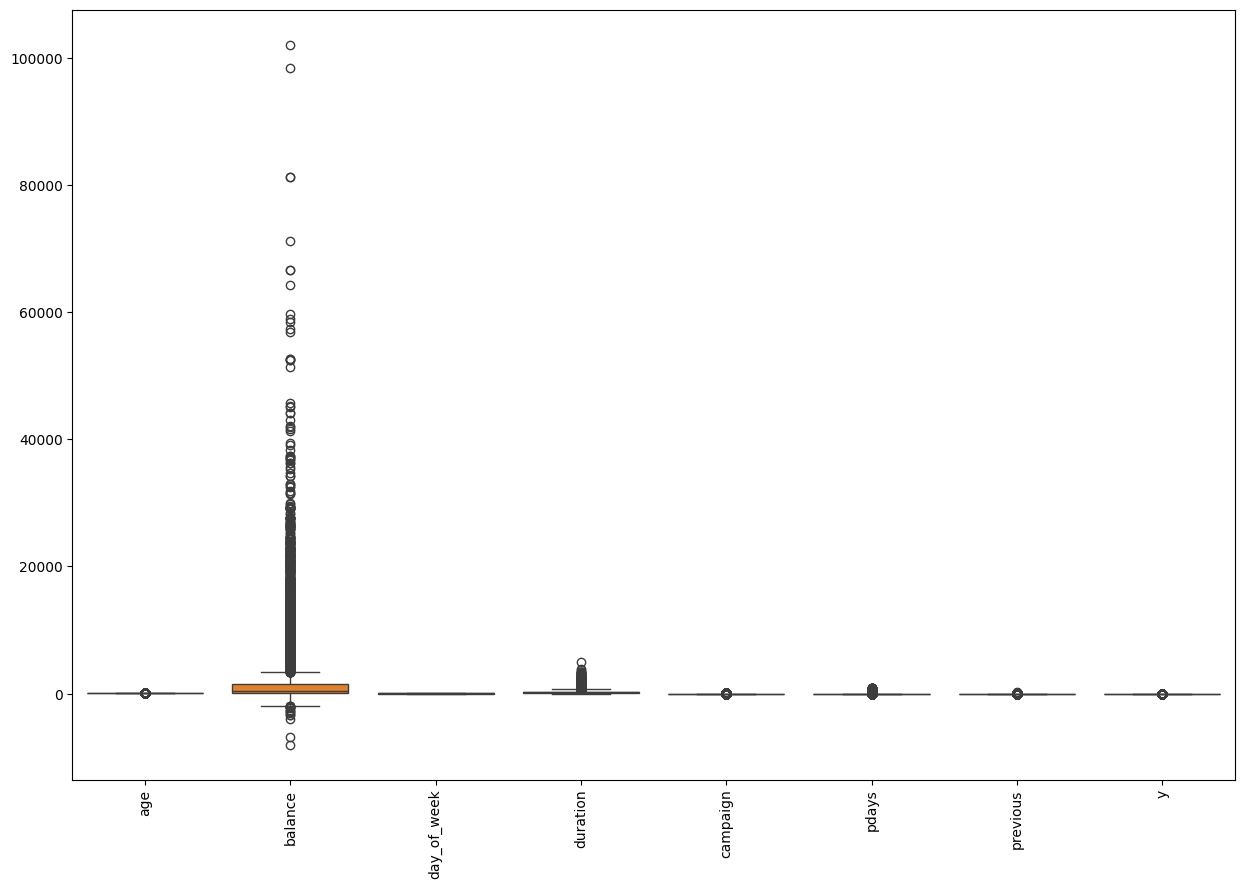

In [ ]:
# Outlier Treatment
plt.figure(figsize = (15,10))
sns.boxplot(data = df.select_dtypes(include = 'number'))
plt.xticks(rotation = 90)
plt.show()

In [ ]:
# Outlier Treatment
columns = ["balance", "duration","pdays"]
for col in columns:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_limit = Q1 - 1.5 * IQR
  upper_limit = Q3 + 1.5 * IQR

  df[col] = np.where(df[col] > upper_limit, upper_limit, np.where(df[col] < lower_limit, lower_limit, df[col]))

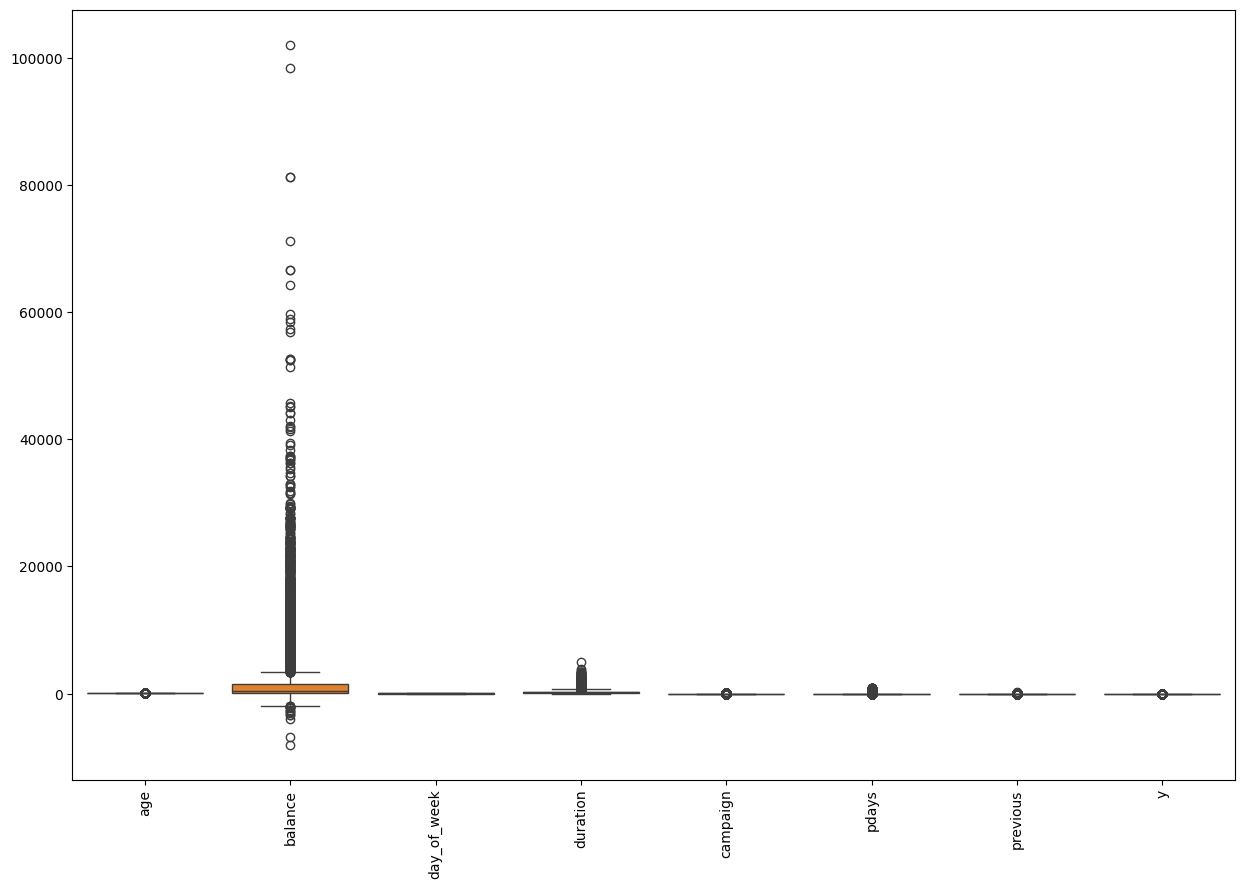

In [ ]:
# Outlier Treatment
plt.figure(figsize = (15,10))
sns.boxplot(data = df.select_dtypes(include = 'number'))
plt.xticks(rotation = 90)
plt.show()

In [ ]:
df.select_dtypes(include = 'object').columns

Index([], dtype='object')

In [ ]:
df = pd.get_dummies(df, drop_first = True, dtype = int)

In [ ]:
df = pd.get_dummies(df, drop_first = True, dtype = int)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          45211 non-null  object
 2   marital      45211 non-null  object
 3   education    45211 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      45211 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     45211 non-null  object
 16  y            45211 non-null  int64 
dtypes: int64(8), object(9)
memory usage: 5.9+ MB


In [ ]:
# Install catboost
!pip install catboost

# Hyper parameter tuning
from catboost import CatBoostClassifier
model1 = CatBoostClassifier(iterations = 200, depth = 6, learning_rate = 0.1, verbose = 0, random_seed = 42)
model1.fit(X_train_encoded, y_train)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.8 MB/s eta 0:00:00


CatBoostClassifier(depth=6, iterations=200, learning_rate=0.1, random_seed=42, verbose=0)

CONFUSION MATRIX:

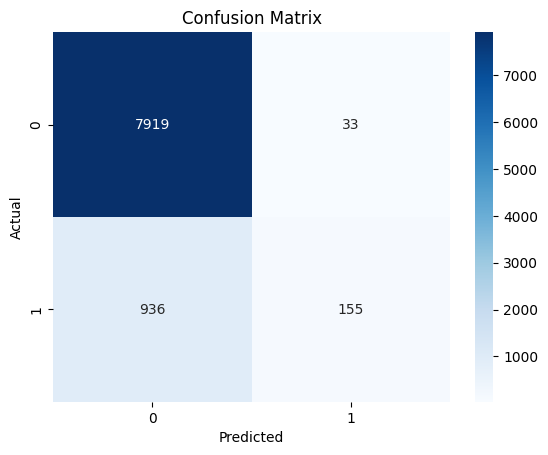

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

ROC-AUC CURVE

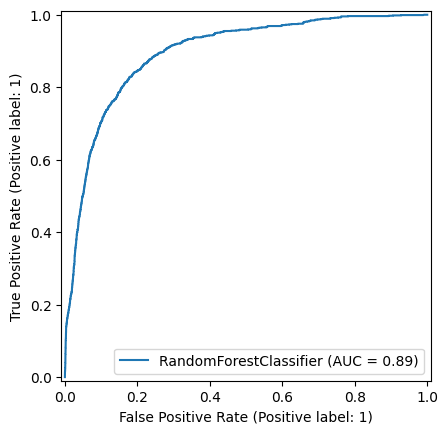

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(model, X_test_encoded, y_test)
plt.show()

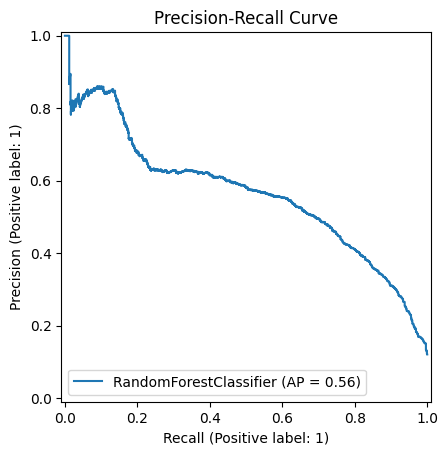

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

# Using the correct estimator API with the encoded test features
PrecisionRecallDisplay.from_estimator(model, X_test_encoded, y_test)
plt.title("Precision-Recall Curve")
plt.show()

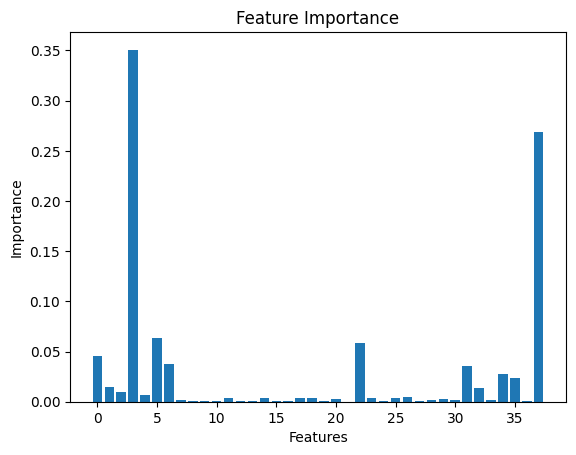

In [ ]:
import matplotlib.pyplot as plt

plt.bar(range(len(model.feature_importances_)),
        model.feature_importances_)
plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

PRECISION & RECAL & F1 SCORE

In [ ]:
from sklearn.metrics import classification_report,accuracy_score
y_pred = model.predict(X_test_encoded)
print(classification_report(y_test, y_pred))
print("Accuracy",accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      1.00      0.94      7952
           1       0.82      0.14      0.24      1091

    accuracy                           0.89      9043
   macro avg       0.86      0.57      0.59      9043
weighted avg       0.89      0.89      0.86      9043

Accuracy 0.8928452947030853


In [ ]:
y.value_counts()

,count
y,
0,39922
1,5289


In [ ]:
y.value_counts(normalize = True)*100

,proportion
y,
0,88.30152
1,11.69848


In [ ]:
y.value_counts(normalize = True)*100

,proportion
y,
0,88.30152
1,11.69848


In [ ]:
print(y.value_counts(dropna = True))
print(y.isna().sum())

y
0    39922
1     5289
Name: count, dtype: int64
0


In [ ]:
print(y.value_counts(dropna = True))
print(y.isna().sum())

y
0    39922
1     5289
Name: count, dtype: int64
0


In [ ]:
# apply smote technique using the encoded training data
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_encoded, y_train)

In [ ]:
# Real time testing
# Extracting the sample from the encoded test set to ensure numerical features
new_customer = X_test_encoded.iloc[0]
new_customer_df = pd.DataFrame([new_customer])
prediction = model1.predict(new_customer_df)
print(prediction)

[0]


In [ ]:
from sklearn.metrics import recall_score, precision_score

print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))

Recall: 0.14207149404216315
Precision: 0.824468085106383


In [ ]:
# Predict using the encoded test set available in the workspace
test_predictions = model.predict(X_test_encoded)
print(test_predictions)

[0 0 0 ... 0 0 0]


In [ ]:
# Create a submission dataframe using test set indices and our actual test predictions
submission_df = pd.DataFrame({
    'Id': X_test_encoded.index,
    'Response': test_predictions
})

# Save to csv
submission_df.to_csv("submit.csv", index=False)
print("Submission file 'submit.csv' saved successfully with shape:", submission_df.shape)

Submission file 'submit.csv' saved successfully with shape: (9043, 2)


In [ ]:
!gzip submit.csv

In [ ]:
!rm submit.csv.gz